
# EDA – Pedidos Ya (Logística)
Análisis exploratorio de las bases **pedidos**, **riders** y **turnos** para el caso *Delivery y tecnología – PedidosYa*.

**Problema de la consigna:** la tasa de aceptación de órdenes es de ~70% (Mercado A) y los un-dispatch (el rider acepta y luego no finaliza) son ~2%. Efectos: (A) la orden no aceptada afecta el **nivel de servicio**; (B) se reduce la **disponibilidad** de riders. Supuestos: una orden simultánea por rider; es viable capitalizar el aumento de UTR en ahorro de CPO. **Pregunta:** propuesta para maximizar la aceptación y la ejecución de las órdenes, y estimar el impacto en nivel de servicio y costos.

**Hilo conductor:** disponibilidad de riders → aceptación → ejecución (reasignación / un-dispatch) → nivel de servicio (Delivery Time, cancelaciones) → eficiencia (UTR, CPO).

Estructura:
1. Carga y calidad de datos
2. Construcción de variables (tiempos por etapa, pago total, hora/día)
3. Tendencias temporales
4. Relaciones entre variables (pedidos)
5. Riders (vehículo, antigüedad, aceptación)
6. Turnos y oferta vs demanda
7. Productividad (pedidos × turnos × riders)
8. Relación entre turnos, riders y pedidos
9. Reasignaciones y un-dispatch (reconstrucción desde las transiciones)
10. Escenarios de impacto (nivel de servicio, UTR y CPO)
11. Validación de hipótesis
12. Hallazgos



## Hipótesis de trabajo
_Objetivo: maximizar la aceptación y la ejecución de las órdenes. Meta numérica: **revisar** (la consigna da el punto de partida: ~70% de aceptación y ~2% de un-dispatch)._

| # | Eje | Hipótesis | Variables | Sección |
|---|---|---|---|---|
| H1 | Disponibilidad | La oferta real de riders es menor que la planificada, con la mayor brecha en los picos | turnos planificados vs reales, pedidos por hora | 8 |
| H2 | Disponibilidad | La oferta acompaña la forma de la demanda; el problema es el cumplimiento, no el perfil horario | riders por hora vs pedidos por hora | 6, 8 |
| H3 | Aceptación | Aceptar más se asocia con más pedidos por hora (UTR) y más ingreso por hora del rider | `tasa_aceptacion`, `ped_hora`, `pago_hora` | 7, 8, 10 |
| H4 | Aceptación | El pago por pedido sigue la distancia, no el tiempo total ni la espera: los pedidos con espera larga son menos atractivos | `pago_base`, distancias, `t_espera_local`, `t_total` | 4 |
| H5 | Aceptación | Los incentivos se concentran en ciertas franjas (noche, picos de cena) y no se relacionan con el esfuerzo del pedido | `pago_incentivos`, `hora`, distancias | 3, 4 |
| H6 | Aceptación | Existe un perfil de rider (`avg_batch` alto) con menor aceptación, más no-show y menos UTR | `avg_batch`, `tasa_aceptacion`, no-show | 5, 8 |
| H7 | Aceptación | La antigüedad mejora puntualidad y productividad, pero no la aceptación | `tenure_in_weeks` | 5, 8 |
| H8 | Ejecución | Hay reasignaciones / abandonos post-aceptación medibles desde las transiciones, concentrados en ciertos segmentos | `transicion`, `transicion_id_repartidor` | 9 |
| H9 | Ejecución | Los pedidos reasignados tienen mayor tiempo total y más cancelaciones | `t_total`, `order_status` | 9 |
| H10 | Ejecución | Mayor distancia al retiro y mayor espera en el local se asocian con más reasignaciones | `pu_distance`, `t_espera_local` | 9 |
| H11 | Impacto | Subir la aceptación reduce los rechazos por orden y el Delivery Time, y mejora UTR y CPO | escenarios | 10 |


In [35]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 50); pd.set_option('display.float_format', '{:,.2f}'.format)
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': .3})

# === RUTAS ===
RUTA_PEDIDOS = 'Base de Pedidos.csv'
RUTA_RIDERS  = 'Base de Riders.csv'
RUTA_TURNOS  = 'Base de Turnos - NUEVA! (1).csv'
MUESTRA_SCATTER = 50_000   # filas para scatterplots

## 1. Carga y calidad de datos

In [36]:
COLS_FECHA_PED = ['creacion_pedido','creacion_transicion','rider_notified_at','rider_accepted_at','rider_near_pickup_at',
                  'rider_picked_up_at','rider_near_dropoff_at','rider_dropped_off_at']
pedidos = pd.read_csv(RUTA_PEDIDOS, low_memory=False)
for col in COLS_FECHA_PED:
    pedidos[col] = pd.to_datetime(pedidos[col], format='mixed', errors='coerce')

riders = pd.read_csv(RUTA_RIDERS)

# Turnos: CSV con inicio/fin planificado y real; los turnos sin horario real (no se conectaron) quedan con NaT
turnos = pd.read_csv(RUTA_TURNOS, dtype={'shift_id': str})
turnos['rider_id'] = turnos['rider_id'].astype('Int64')
for col in ['inicio_turno_planificado','inicio_turno_real','fin_turno_planificado','fin_turno_real']:
    turnos[col] = pd.to_datetime(turnos[col], errors='coerce')
turnos['inicio'] = turnos['inicio_turno_real']
turnos['fin']    = turnos['fin_turno_real']
turnos['duracion_hs'] = (turnos['fin'] - turnos['inicio']).dt.total_seconds() / 3600

for nombre, df in [('pedidos', pedidos), ('riders', riders), ('turnos', turnos)]:
    print(f'{nombre}: {df.shape}')

pedidos: (1217343, 21)
riders: (8736, 5)
turnos: (78377, 9)


In [37]:
# Nulos
for nombre, df in [('pedidos', pedidos), ('riders', riders), ('turnos', turnos)]:
    n = df.isna().sum(); n = n[n > 0]
    print(f'--- Nulos en {nombre} ---'); print((pd.DataFrame({'nulos': n, '%': n / len(df) * 100})) if len(n) else 'sin nulos')

--- Nulos en pedidos ---
                       nulos    %
rider_near_dropoff_at   2398 0.20
rider_dropped_off_at    5833 0.48
--- Nulos en riders ---
           nulos     %
avg_batch   1048 12.00
--- Nulos en turnos ---
                   nulos     %
inicio_turno_real  27127 34.61
fin_turno_real     27127 34.61
inicio             27127 34.61
fin                27127 34.61
duracion_hs        27127 34.61


In [38]:
# ¿1 fila = 1 pedido o hay varias filas por pedido (transiciones)?
print('filas:', len(pedidos), '| id_pedido únicos:', pedidos['id_pedido'].nunique())
print(pedidos['order_status'].value_counts(dropna=False), '\n')
print(pedidos['transicion'].value_counts(dropna=False).head(15))
print('\nriders únicos en pedidos:', pedidos['id_repartidor'].nunique(), '| comercios:', pedidos['id_comercio'].nunique())
print('id_repartidor != transicion_id_repartidor:', (pedidos['id_repartidor'] != pedidos['transicion_id_repartidor']).mean().round(4))
print('duplicados riders:', riders['id_repartidor'].duplicated().sum(), '| duplicados shift_id:', turnos['shift_id'].duplicated().sum())

filas: 1217343 | id_pedido únicos: 329196
order_status
completed    1210706
cancelled       6634
pending            3
Name: count, dtype: int64 

transicion
accepted       346554
near_pickup    340117
picked_up      329196
queued         201476
Name: count, dtype: int64

riders únicos en pedidos: 5288 | comercios: 2640
id_repartidor != transicion_id_repartidor: 0.1874
duplicados riders: 446 | duplicados shift_id: 0


In [39]:
# Una fila por pedido (última transición registrada). REVISAR este criterio según la consigna.
pedidos = pedidos.sort_values('creacion_transicion')
ped = pedidos.drop_duplicates('id_pedido', keep='last').copy()
print('Pedidos únicos:', len(ped))

Pedidos únicos: 329196


## 2. Construcción de variables

In [40]:
mins = lambda a, b: (ped[a] - ped[b]).dt.total_seconds() / 60
ped['t_aceptacion']   = mins('rider_accepted_at',    'rider_notified_at')    # min que tarda en aceptar
ped['t_a_local']      = mins('rider_near_pickup_at', 'rider_accepted_at')    # min hasta llegar al local
ped['t_espera_local'] = mins('rider_picked_up_at',   'rider_near_pickup_at') # min esperando en el local
ped['t_viaje']        = mins('rider_dropped_off_at', 'rider_picked_up_at')   # min de retiro a entrega
ped['t_total']        = mins('rider_dropped_off_at', 'rider_notified_at')    # notificación a entrega
ped['pago_total']     = ped[['pago_base','pago_rendimiento','pago_incentivos']].sum(axis=1)
ped['dist_total']     = ped['pu_distance'] + ped['do_distance']
ped['undispatch_total'] = ped['pre_accept_undispatch'] + ped['post_accept_undispatchs']
ped['entregado']      = ped['rider_dropped_off_at'].notna()
ped['fecha'] = ped['rider_notified_at'].dt.date
ped['hora']  = ped['rider_notified_at'].dt.hour
ped['dow']   = ped['rider_notified_at'].dt.dayofweek   # 0 = lunes
ped['semana']= ped['rider_notified_at'].dt.to_period('W').dt.start_time

TIEMPOS = ['t_aceptacion','t_a_local','t_espera_local','t_viaje','t_total']
print('Tiempos negativos por variable:'); print((ped[TIEMPOS] < 0).sum())
print('\nDescriptivos:'); print(ped[TIEMPOS + ['pu_distance','do_distance','pago_base','pago_rendimiento','pago_incentivos','pago_total']].describe(percentiles=[.05,.5,.95,.99]).T)

Tiempos negativos por variable:
t_aceptacion      0
t_a_local         0
t_espera_local    0
t_viaje           0
t_total           0
dtype: int64

Descriptivos:
                      count     mean    std  min     5%      50%      95%  \
t_aceptacion     329,196.00     0.26   0.30 0.00   0.02     0.17     0.85   
t_a_local        329,196.00     3.16   2.84 0.00   0.00     2.79     8.27   
t_espera_local   329,196.00     5.29   4.90 0.00   0.59     3.86    14.66   
t_viaje          327,855.00     9.69   4.67 1.00   4.01     8.84    18.17   
t_total          327,855.00    18.41   7.11 1.03   9.28    17.27    31.24   
pu_distance      329,196.00   506.01 444.01 0.00  36.00   397.00 1,321.00   
do_distance      329,196.00 1,352.15 994.74 0.00 248.00 1,098.00 3,298.00   
pago_base        329,196.00    18.06   4.91 0.00  12.12    16.89    26.66   
pago_rendimiento 329,196.00     1.37   1.23 0.00   0.00     1.46     3.59   
pago_incentivos  329,196.00     1.57   3.50 0.00   0.00     0.00     8

In [41]:
# Limpieza: sólo entregados, tiempos >= 0 y se recorta el 1% superior (REVISAR umbral)
ok = ped['entregado'] & (ped[TIEMPOS] >= 0).all(axis=1)
lim = ped.loc[ok, TIEMPOS].quantile(.99)
ok &= (ped[TIEMPOS] <= lim).all(axis=1)
pe = ped[ok].copy()
print(f'Se conservan {len(pe):,} de {len(ped):,} pedidos ({len(pe)/len(ped):.1%}). No entregados: {(~ped.entregado).sum():,}')

Se conservan 314,541 de 329,196 pedidos (95.5%). No entregados: 1,341


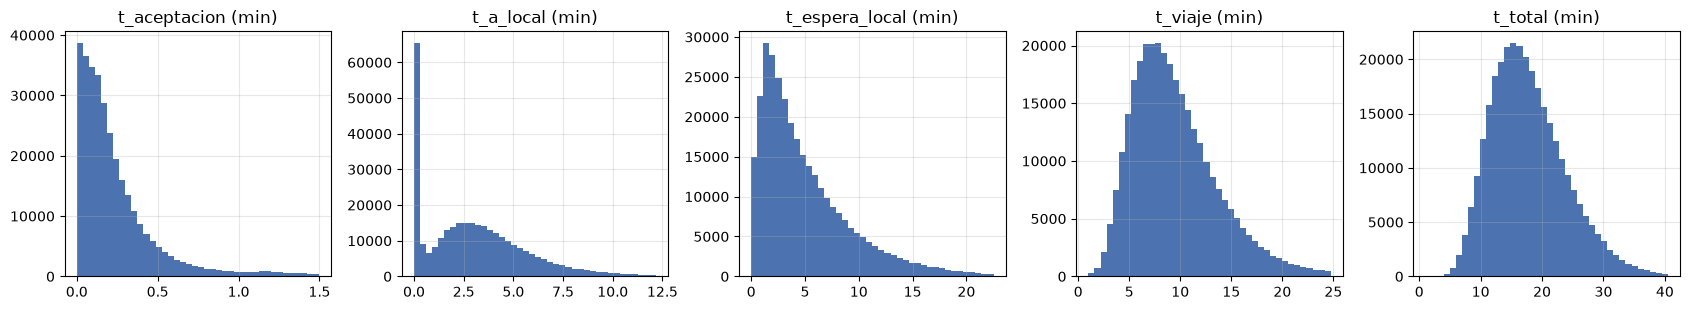

In [42]:
fig, ax = plt.subplots(1, 5, figsize=(17, 3.2))
for a, c in zip(ax, TIEMPOS):
    a.hist(pe[c], bins=40, color='#4c72b0'); a.set_title(c + ' (min)')
plt.tight_layout(); plt.show()

## 3. Tendencias temporales
_Hipótesis: H5 (incentivos por franja) y contexto de H1 (picos de demanda)._

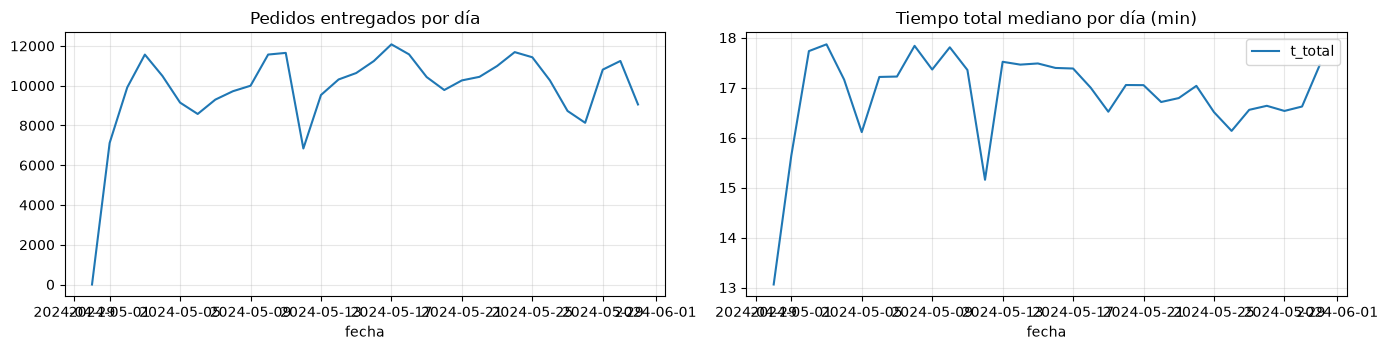

In [43]:
diario = pe.groupby('fecha').agg(pedidos=('id_pedido','count'), t_total=('t_total','median'), pago=('pago_total','mean'))
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
diario['pedidos'].plot(ax=ax[0], title='Pedidos entregados por día')
diario[['t_total']].plot(ax=ax[1], title='Tiempo total mediano por día (min)')
plt.tight_layout(); plt.show()

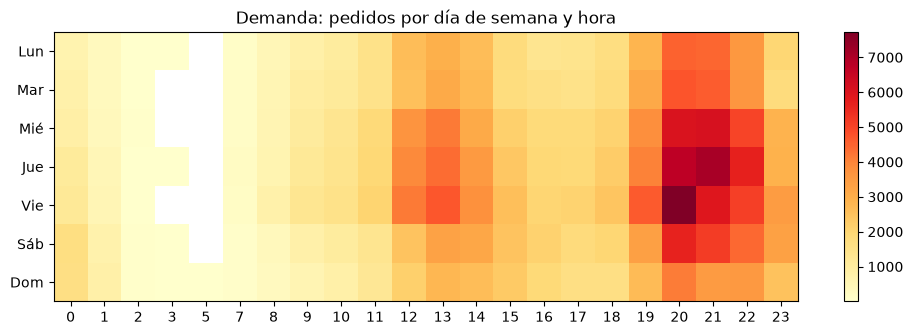

In [44]:
heat = pe.pivot_table(index='dow', columns='hora', values='id_pedido', aggfunc='count').reindex(range(7))
fig, ax = plt.subplots(figsize=(12, 3.5))
im = ax.imshow(heat.values, aspect='auto', cmap='YlOrRd'); ax.grid(False)
ax.set_yticks(range(7)); ax.set_yticklabels(['Lun','Mar','Mié','Jue','Vie','Sáb','Dom'])
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns)
ax.set_title('Demanda: pedidos por día de semana y hora'); plt.colorbar(im); plt.show()

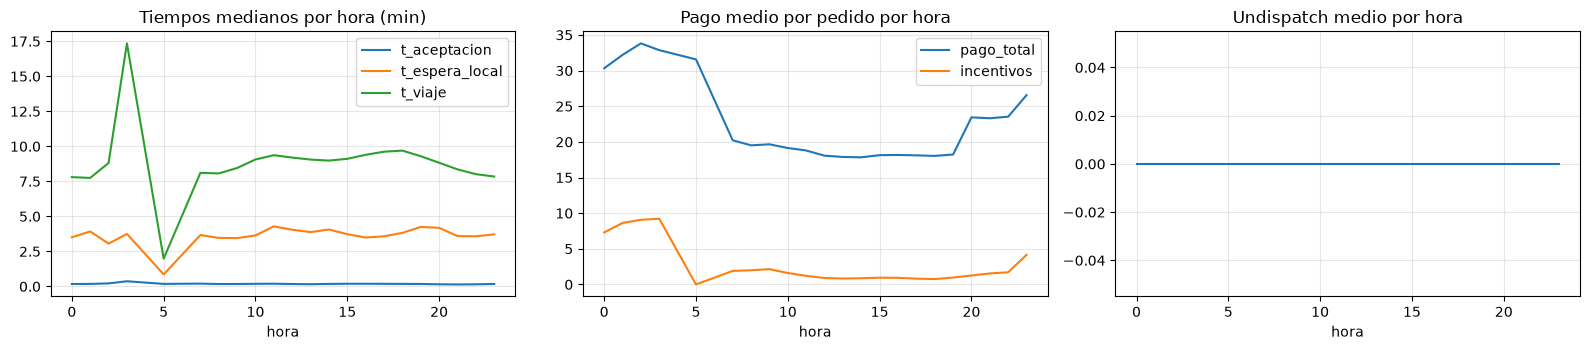

,pedidos,t_aceptacion,t_espera_local,t_viaje,pago_total,incentivos,undispatch
hora,,,,,,,
0,7712,0.17,3.51,7.80,30.32,7.30,0.00
1,3453,0.18,3.92,7.75,32.20,8.62,0.00
2,255,0.22,3.05,8.81,33.81,9.07,0.00
3,6,0.37,3.75,17.35,32.86,9.21,0.00
5,1,0.18,0.86,1.98,31.57,0.00,0.00
7,906,0.20,3.67,8.11,20.22,1.90,0.00
8,3515,0.17,3.46,8.07,19.51,1.99,0.00
9,6610,0.17,3.45,8.45,19.65,2.14,0.00
10,8137,0.19,3.64,9.06,19.14,1.60,0.00


In [45]:
por_hora = pe.groupby('hora').agg(pedidos=('id_pedido','count'), t_aceptacion=('t_aceptacion','median'),
                                  t_espera_local=('t_espera_local','median'), t_viaje=('t_viaje','median'),
                                  pago_total=('pago_total','mean'), incentivos=('pago_incentivos','mean'),
                                  undispatch=('undispatch_total','mean'))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
por_hora[['t_aceptacion','t_espera_local','t_viaje']].plot(ax=ax[0], title='Tiempos medianos por hora (min)')
por_hora[['pago_total','incentivos']].plot(ax=ax[1], title='Pago medio por pedido por hora')
por_hora['undispatch'].plot(ax=ax[2], title='Undispatch medio por hora')
plt.tight_layout(); plt.show()
por_hora

## 4. Relaciones entre variables (pedidos)
_Hipótesis: H4 (pago vs esfuerzo), H5 y H10. `pu_distance` = rider → local; `do_distance` = local → cliente. Las columnas de undispatch dan 0 en esta tabla (una fila por pedido): se reconstruyen en la sección 9._

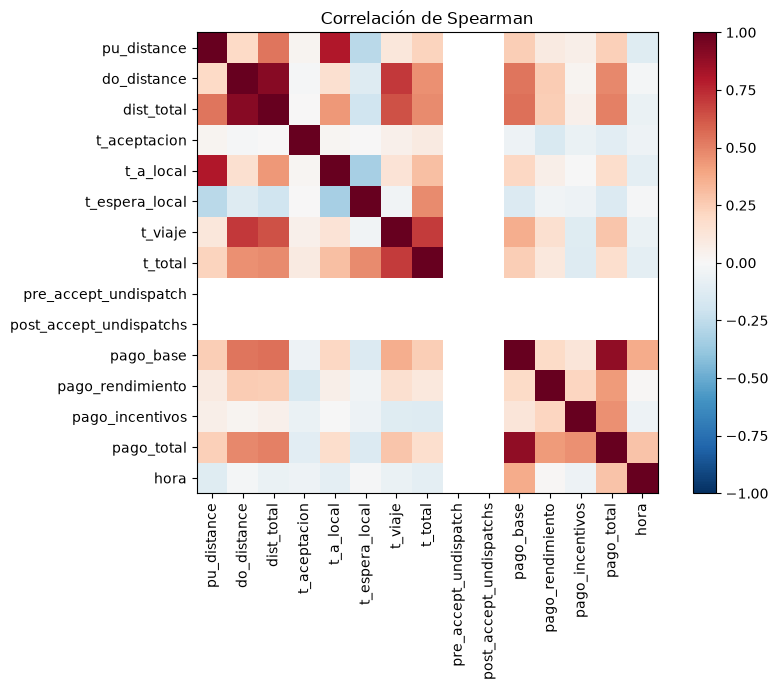

In [46]:
VARS = ['pu_distance','do_distance','dist_total','t_aceptacion','t_a_local','t_espera_local','t_viaje','t_total',
        'pre_accept_undispatch','post_accept_undispatchs','pago_base','pago_rendimiento','pago_incentivos','pago_total','hora']
corr = pe[VARS].corr(method='spearman')
fig, ax = plt.subplots(figsize=(9, 7)); im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(VARS))); ax.set_xticklabels(VARS, rotation=90); ax.set_yticks(range(len(VARS))); ax.set_yticklabels(VARS)
ax.set_title('Correlación de Spearman'); plt.colorbar(im); plt.tight_layout(); plt.show()

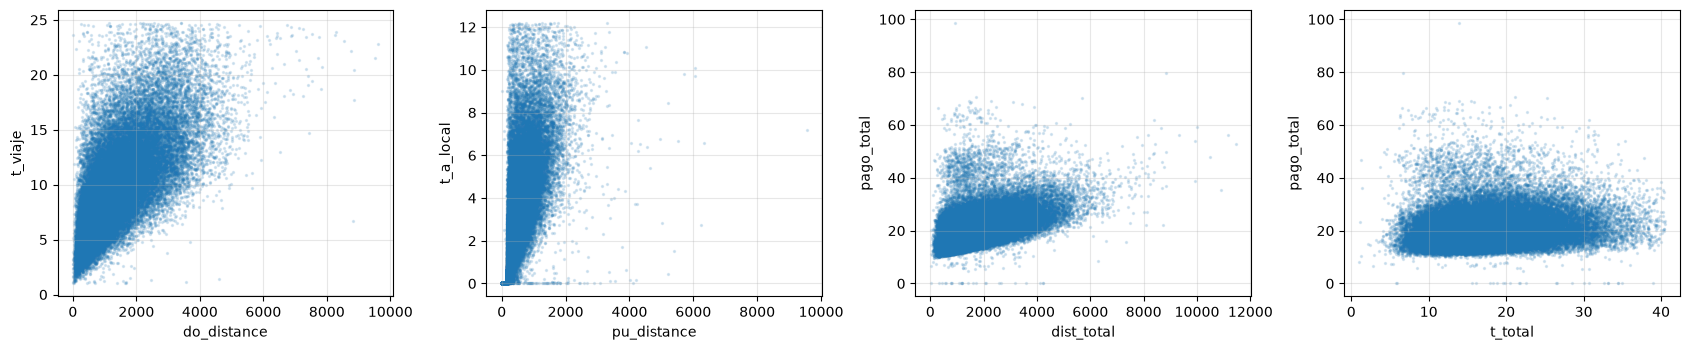

In [47]:
s = pe.sample(min(MUESTRA_SCATTER, len(pe)), random_state=0)
pares = [('do_distance','t_viaje'), ('pu_distance','t_a_local'), ('dist_total','pago_total'), ('t_total','pago_total')]
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a, (x, y) in zip(ax, pares):
    a.scatter(s[x], s[y], s=2, alpha=.15); a.set_xlabel(x); a.set_ylabel(y)
plt.tight_layout(); plt.show()

In [48]:
# Efecto de los undispatch y del pago sobre los tiempos
for v in ['pre_accept_undispatch','post_accept_undispatchs']:
    g = pe.assign(g=pe[v].clip(upper=3)).groupby('g')[['t_aceptacion','t_total']].agg(['median','count'])
    print(f'\n{v} (3 = 3 o más)'); print(g)
pe['dec_incentivo'] = pd.qcut(pe['pago_incentivos'].rank(method='first'), 5, labels=['Q1','Q2','Q3','Q4','Q5'])
print('\nIncentivo (quintiles) vs tiempo de aceptación y espera'); print(pe.groupby('dec_incentivo', observed=True)[['pago_incentivos','t_aceptacion','t_total']].median())


pre_accept_undispatch (3 = 3 o más)
  t_aceptacion         t_total        
        median   count  median   count
g                                     
0         0.17  314541   17.01  314541

post_accept_undispatchs (3 = 3 o más)
  t_aceptacion         t_total        
        median   count  median   count
g                                     
0         0.17  314541   17.01  314541

Incentivo (quintiles) vs tiempo de aceptación y espera
               pago_incentivos  t_aceptacion  t_total
dec_incentivo                                        
Q1                        0.00          0.18    17.98
Q2                        0.00          0.18    17.65
Q3                        0.00          0.18    17.14
Q4                        1.79          0.16    16.75
Q5                        3.80          0.15    15.69


             pedidos  espera_med  espera_p90  t_total  peso_espera
id_comercio                                                       
96787926          38       11.28       14.87    27.46         0.41
105902808         39       11.17       15.51    25.81         0.43
35314266         740       10.05       15.43    24.45         0.41
91322970          34        9.95       16.12    25.34         0.39
58210734         123        9.50       15.27    22.62         0.42
41945124          60        9.33       14.31    18.96         0.49
57958926          52        8.88       15.88    21.64         0.41
35060394         519        8.85       14.96    22.50         0.39
108762222        150        8.83       14.11    23.75         0.37
30108858          60        8.77       17.59    20.67         0.42

Peso mediano de la espera en el tiempo total: 0.21 | dispersión de espera mediana entre comercios (desvío): 1.53


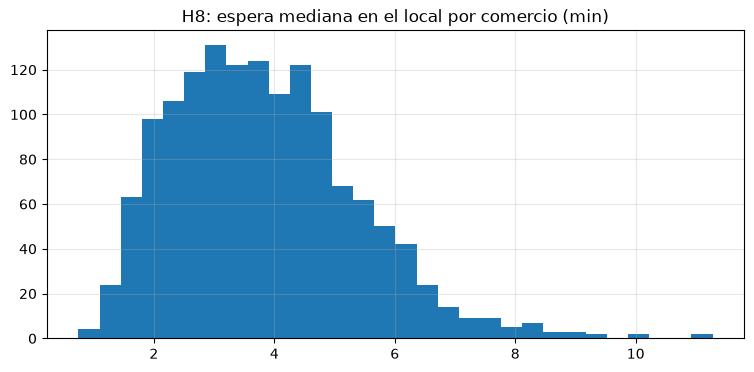

In [49]:
# H8: espera en el local por comercio (comercios con al menos 30 pedidos)
com = pe.groupby('id_comercio').agg(pedidos=('id_pedido','count'), espera_med=('t_espera_local','median'), espera_p90=('t_espera_local', lambda x: x.quantile(.9)),
                                   t_total=('t_total','median')).query('pedidos >= 30')
com['peso_espera'] = com['espera_med'] / com['t_total']
print(com.sort_values('espera_med', ascending=False).head(10))
print('\nPeso mediano de la espera en el tiempo total:', com['peso_espera'].median().round(2),
      '| dispersión de espera mediana entre comercios (desvío):', com['espera_med'].std().round(2))
com['espera_med'].hist(bins=30); plt.title('H8: espera mediana en el local por comercio (min)'); plt.show()

## 5. Riders
_Hipótesis: H3, H6, H7._

                   count unique        top  freq          mean           std  \
id_repartidor   8,736.00    NaN        NaN   NaN 85,436,928.94 37,737,110.11   
vehicle_name        8736      5  Bicicleta  5072           NaN           NaN   
tasa_aceptacion 8,736.00    NaN        NaN   NaN          0.80          0.20   
avg_batch       7,688.00    NaN        NaN   NaN          4.45          1.73   
tenure_in_weeks 8,736.00    NaN        NaN   NaN         59.12         64.39   

                         min           25%           50%            75%  \
id_repartidor   4,009,062.00 54,351,312.00 95,024,496.00 120,091,969.50   
vehicle_name             NaN           NaN           NaN            NaN   
tasa_aceptacion         0.03          0.67          0.85           1.00   
avg_batch               1.00          3.00          4.57           5.53   
tenure_in_weeks         0.00         10.00         33.14          91.29   

                           max  
id_repartidor   135,168,522.00  
ve

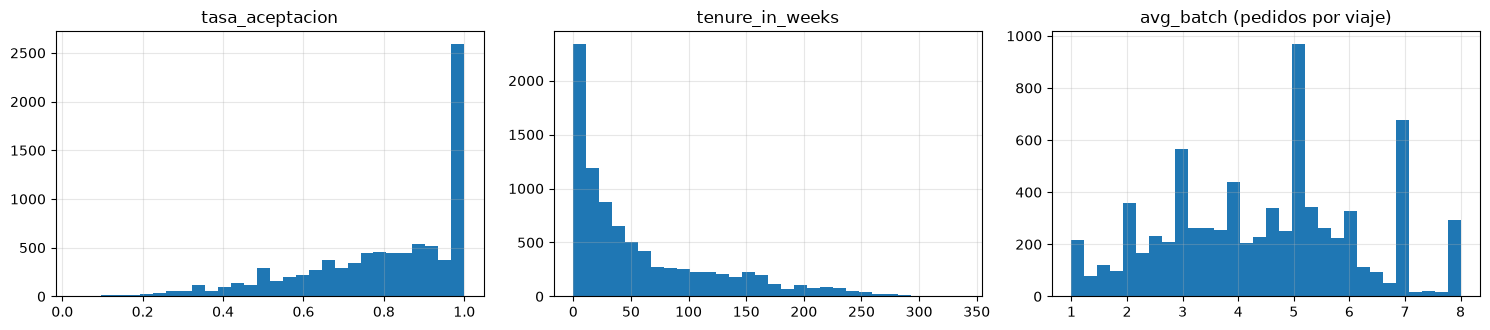

                 tasa_aceptacion  avg_batch  tenure_in_weeks
tasa_aceptacion             1.00      -0.26            -0.02
avg_batch                  -0.26       1.00            -0.42
tenure_in_weeks            -0.02      -0.42             1.00


In [50]:
print(riders.describe(include='all').T)
print(riders['vehicle_name'].value_counts())
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
riders['tasa_aceptacion'].hist(ax=ax[0], bins=30); ax[0].set_title('tasa_aceptacion')
riders['tenure_in_weeks'].hist(ax=ax[1], bins=30); ax[1].set_title('tenure_in_weeks')
riders['avg_batch'].hist(ax=ax[2], bins=30); ax[2].set_title('avg_batch (pedidos por viaje)')
plt.tight_layout(); plt.show()
print(riders[['tasa_aceptacion','avg_batch','tenure_in_weeks']].corr(method='spearman'))

In [51]:
pr = pe.merge(riders, on='id_repartidor', how='left')
print('Pedidos sin rider en tabla riders:', pr['vehicle_name'].isna().sum())
por_veh = pr.groupby('vehicle_name').agg(pedidos=('id_pedido','count'), riders=('id_repartidor','nunique'), dist_entrega=('do_distance','median'),
                                         t_viaje=('t_viaje','median'), t_total=('t_total','median'), pago_total=('pago_total','mean'))
por_veh['pedidos_por_rider'] = por_veh['pedidos'] / por_veh['riders']
por_veh

Pedidos sin rider en tabla riders: 96


,pedidos,riders,dist_entrega,t_viaje,t_total,pago_total,pedidos_por_rider
vehicle_name,,,,,,,
Automovil,769,40,"1,302.00",9.44,17.66,20.62,19.23
Bicicleta,195259,3104,883.00,8.17,16.39,19.59,62.91
CAFE - Bici,4415,35,855.00,7.98,16.50,19.70,126.14
CAFE - Moto,686,22,"1,428.00",9.00,17.49,22.79,31.18
Motocicleta,138476,2145,"1,480.00",9.56,17.76,22.90,64.56


In [52]:
pr['tenure_grupo'] = pd.cut(pr['tenure_in_weeks'], [-1, 4, 12, 26, 52, 1e9], labels=['<=4 sem','5-12','13-26','27-52','>52'])
print(pr.groupby('tenure_grupo', observed=True).agg(pedidos=('id_pedido','count'), t_aceptacion=('t_aceptacion','median'),
      t_total=('t_total','median'), pago_total=('pago_total','mean'), undispatch=('undispatch_total','mean')))
r_ped = pr.groupby('id_repartidor').agg(pedidos=('id_pedido','count'), t_total=('t_total','median'), undisp=('undispatch_total','mean'),
                                        pago=('pago_total','mean')).join(riders.set_index('id_repartidor'))
print(r_ped[['pedidos','t_total','undisp','pago','tasa_aceptacion','avg_batch','tenure_in_weeks']].corr(method='spearman').round(2))

              pedidos  t_aceptacion  t_total  pago_total  undispatch
tenure_grupo                                                        
<=4 sem          4363          0.16    18.29       19.88        0.00
5-12            14081          0.16    17.85       19.97        0.00
13-26           42276          0.18    17.59       19.80        0.00
27-52           76828          0.17    16.90       20.73        0.00
>52            202057          0.17    16.75       21.36        0.00
                 pedidos  t_total  undisp  pago  tasa_aceptacion  avg_batch  \
pedidos             1.00    -0.13     NaN  0.14            -0.25      -0.17   
t_total            -0.13     1.00     NaN  0.08             0.12       0.03   
undisp               NaN      NaN     NaN   NaN              NaN        NaN   
pago                0.14     0.08     NaN  1.00             0.21      -0.43   
tasa_aceptacion    -0.25     0.12     NaN  0.21             1.00      -0.39   
avg_batch          -0.17     0.03     NaN -

## 6. Turnos y oferta vs demanda
_Hipótesis: H2._

Turnos sin fechas: 27127 (34.6%)
duracion_hs <= 0: 0 | > 12 hs: 10
count   51,250.00
mean         3.87
std          1.73
min          0.00
25%          3.37
50%          3.87
75%          4.64
max        265.26
Name: duracion_hs, dtype: float64


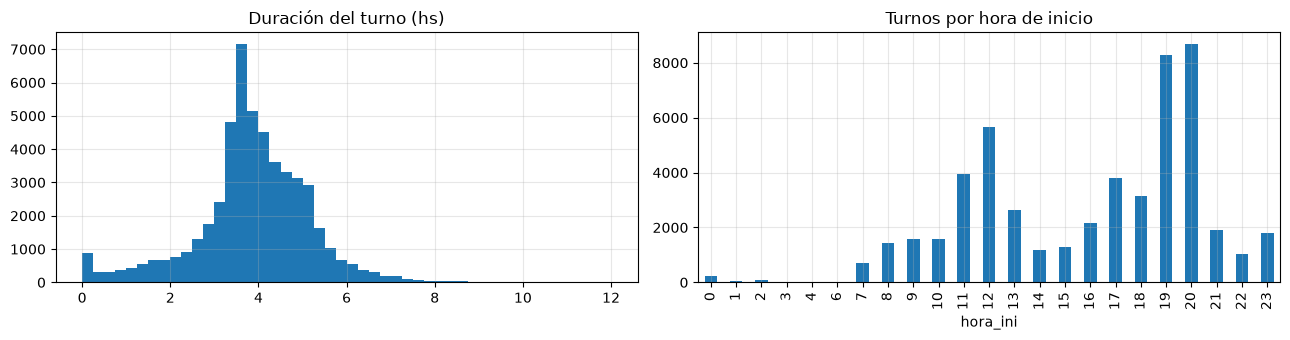

In [53]:
print('Turnos sin fechas:', turnos['inicio'].isna().sum(), f"({turnos['inicio'].isna().mean():.1%})")
tu = turnos.dropna(subset=['inicio','fin']).copy()
print('duracion_hs <= 0:', (tu['duracion_hs'] <= 0).sum(), '| > 12 hs:', (tu['duracion_hs'] > 12).sum())
print(tu['duracion_hs'].describe())
tu['hora_ini'] = tu['inicio'].dt.hour
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
tu['duracion_hs'].clip(upper=12).hist(ax=ax[0], bins=48); ax[0].set_title('Duración del turno (hs)')
tu['hora_ini'].value_counts().sort_index().plot.bar(ax=ax[1], title='Turnos por hora de inicio')
plt.tight_layout(); plt.show()

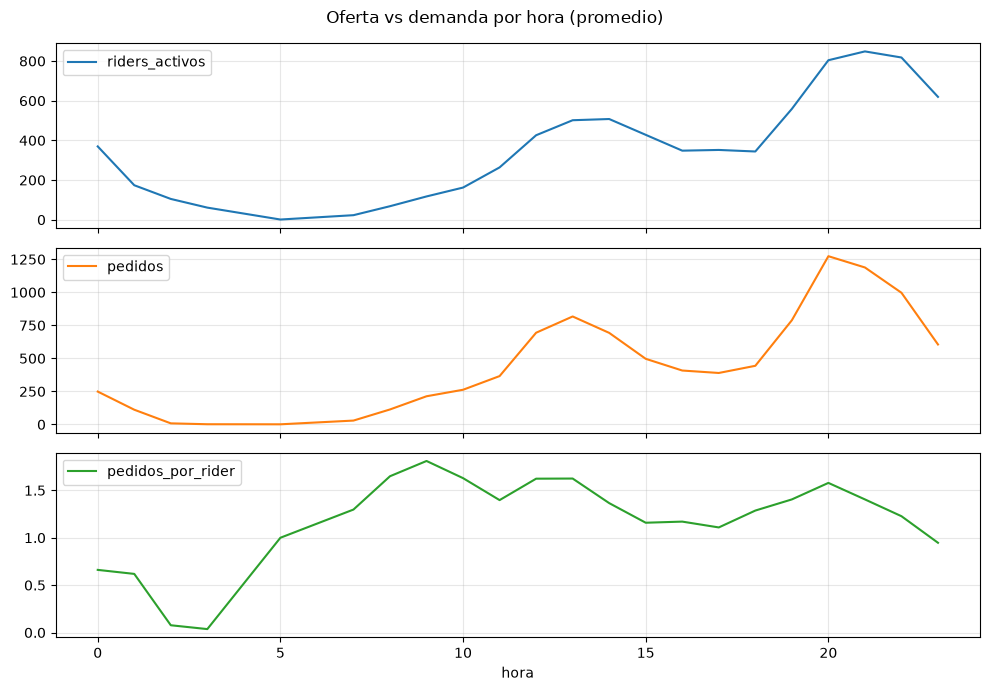

Correlación horaria riders activos vs pedidos: 0.93


In [54]:
# Riders conectados por hora (turnos que cubren cada hora) vs pedidos
tu['h0'] = tu['inicio'].dt.floor('h'); tu['h1'] = tu['fin'].dt.floor('h')
tu = tu[(tu['h1'] >= tu['h0']) & (tu['duracion_hs'] <= 24)]
rep = tu.loc[tu.index.repeat(((tu['h1'] - tu['h0']).dt.total_seconds() // 3600 + 1).astype(int))].copy()
rep['h'] = rep['h0'] + pd.to_timedelta(rep.groupby(level=0).cumcount(), unit='h')
oferta = rep.groupby('h')['rider_id'].nunique().rename('riders_activos')
demanda = pe.groupby(pe['rider_notified_at'].dt.floor('h'))['id_pedido'].count().rename('pedidos')
od = pd.concat([oferta, demanda], axis=1).dropna(); od['pedidos_por_rider'] = od['pedidos'] / od['riders_activos']
od['hora'] = od.index.hour
od.groupby('hora')[['riders_activos','pedidos','pedidos_por_rider']].mean().plot(subplots=True, figsize=(10, 7), title='Oferta vs demanda por hora (promedio)')
plt.tight_layout(); plt.show()
print('Correlación horaria riders activos vs pedidos:', od[['riders_activos','pedidos']].corr(method='spearman').iloc[0, 1].round(2))

## 7. Productividad (pedidos × turnos × riders)
_Hipótesis: H3 y H6._

In [55]:
tu['fecha'] = tu['inicio'].dt.date
hs = tu.groupby(['rider_id','fecha'])['duracion_hs'].sum().rename('horas').reset_index().rename(columns={'rider_id':'id_repartidor'})
pd_rd = pe.groupby(['id_repartidor','fecha']).agg(pedidos=('id_pedido','count'), pago=('pago_total','sum')).reset_index()
prod = pd_rd.merge(hs, on=['id_repartidor','fecha'], how='inner')
prod = prod[(prod['horas'] > .5) & (prod['horas'] <= 16)]
prod['ped_hora'] = prod['pedidos'] / prod['horas']; prod['pago_hora'] = prod['pago'] / prod['horas']
print(f'Rider-día con turno y pedidos: {len(prod):,} (de {len(pd_rd):,} rider-día con pedidos)')
print(prod[['horas','pedidos','ped_hora','pago_hora']].describe())
prod = prod.merge(riders, on='id_repartidor', how='left')
print(prod.groupby('vehicle_name')[['ped_hora','pago_hora']].median())
print(prod[['horas','pedidos','ped_hora','pago_hora','tasa_aceptacion','avg_batch','tenure_in_weeks']].corr(method='spearman').round(2))

Rider-día con turno y pedidos: 31,520 (de 45,244 rider-día con pedidos)
          horas   pedidos  ped_hora  pago_hora
count 31,520.00 31,520.00 31,520.00  31,520.00
mean       6.08      9.06      1.49      31.31
std        2.73      5.75      0.69      16.79
min        0.51      1.00      0.07       0.00
25%        3.85      5.00      1.01      19.38
50%        5.24      8.00      1.47      29.57
75%        8.10     12.00      1.93      40.75
max       15.99     42.00     14.23     259.84
              ped_hora  pago_hora
vehicle_name                     
Automovil         0.74      16.98
Bicicleta         1.44      27.10
CAFE - Bici       1.57      30.41
CAFE - Moto       1.51      34.09
Motocicleta       1.54      33.97
                 horas  pedidos  ped_hora  pago_hora  tasa_aceptacion  \
horas             1.00     0.70      0.03       0.05            -0.04   
pedidos           0.70     1.00      0.69       0.65             0.10   
ped_hora          0.03     0.69      1.00       

## 8. Relación entre turnos, riders y pedidos
_Preguntas: ¿las tres tablas se pueden cruzar (claves, período)? ¿Qué parte de los pedidos se entrega dentro de un turno registrado? ¿Cuánto del turno se usa en pedidos? ¿Qué rider cumple, llega tarde o no se conecta, y cómo se relaciona con su perfil (vehículo, antigüedad, aceptación)? Relacionada con H1, H2, H3, H6 y H7._

Claves: `pedidos.id_repartidor` = `riders.id_repartidor` = `turnos.rider_id`. Un pedido se asigna a un turno si el rider tiene un turno con `inicio_turno_real <= rider_notified_at <= fin_turno_real`.

In [56]:
# 8.1 Integridad de claves y período en común
ped_ok = ped.dropna(subset=['id_repartidor', 'rider_notified_at']).copy()
ped_ok['id_repartidor'] = ped_ok['id_repartidor'].astype('int64')
tr = turnos.dropna(subset=['rider_id']).copy(); tr['rider_id'] = tr['rider_id'].astype('int64')
real = tr.dropna(subset=['inicio_turno_real', 'fin_turno_real']).sort_values('inicio_turno_real')

S_ped, S_tur, S_rid = set(ped_ok['id_repartidor']), set(tr['rider_id']), set(riders['id_repartidor'])
print(pd.DataFrame({
    'riders únicos': [len(S_ped), len(S_tur), len(S_rid)],
    'están en riders': [len(S_ped & S_rid), len(S_tur & S_rid), len(S_rid)],
    'están en turnos': [len(S_ped & S_tur), len(S_tur), len(S_rid & S_tur)],
    'están en pedidos': [len(S_ped), len(S_tur & S_ped), len(S_rid & S_ped)]}, index=['pedidos', 'turnos', 'riders']))

DESDE = max(ped_ok['rider_notified_at'].min(), tr['inicio_turno_planificado'].min())
HASTA = min(ped_ok['rider_notified_at'].max(), tr['fin_turno_planificado'].max())
print(f"\nPedidos : {ped_ok['rider_notified_at'].min():%Y-%m-%d} -> {ped_ok['rider_notified_at'].max():%Y-%m-%d}")
print(f"Turnos  : {tr['inicio_turno_planificado'].min():%Y-%m-%d} -> {tr['fin_turno_planificado'].max():%Y-%m-%d}")
print(f'Período en común (se usa en toda la sección): {DESDE:%Y-%m-%d} -> {HASTA:%Y-%m-%d}')

         riders únicos  están en riders  están en turnos  están en pedidos
pedidos           5288             5206             3285              5288
turnos            3848             3462             3848              3285
riders            8290             8290             3462              5206

Pedidos : 2024-04-30 -> 2024-05-31
Turnos  : 2024-04-30 -> 2024-06-01
Período en común (se usa en toda la sección): 2024-04-30 -> 2024-05-31


                                         pedidos   pct
causa                                                 
dentro de un turno                        288268 87.57
rider con turnos, pero fuera de horario    23225  7.06
rider sin ningún turno                     17703  5.38


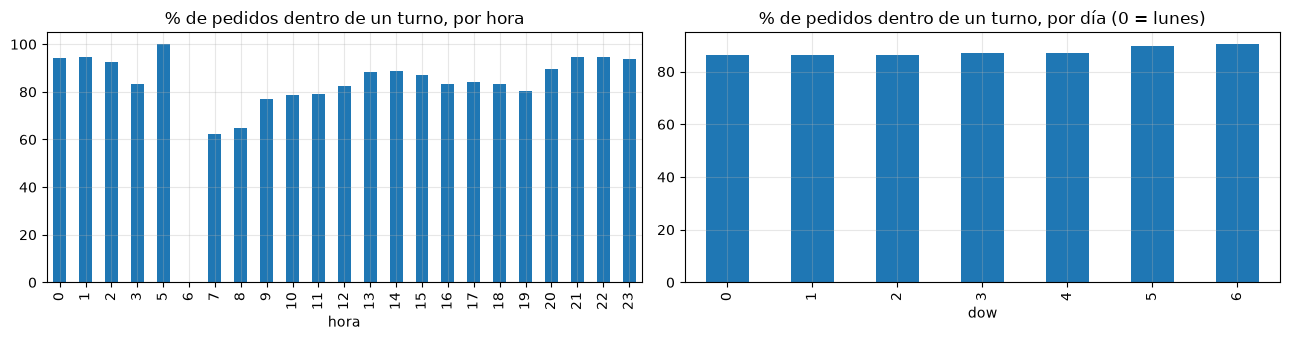

Mediana t_aceptacion (min):
en_turno
False   0.21
True    0.17
Name: t_aceptacion, dtype: float64


In [57]:
# 8.2 Pedido -> turno: ¿cuántos pedidos se entregan dentro de un turno registrado?
p = ped_ok[ped_ok['rider_notified_at'].between(DESDE, HASTA)].sort_values('rider_notified_at')
m = pd.merge_asof(p[['id_pedido','id_repartidor','rider_notified_at','t_aceptacion','entregado','pago_total','hora','dow']],
                  real[['shift_id','rider_id','inicio_turno_real','fin_turno_real']],
                  left_on='rider_notified_at', right_on='inicio_turno_real', left_by='id_repartidor', right_by='rider_id', direction='backward')
m['en_turno'] = m['fin_turno_real'] >= m['rider_notified_at']
m.loc[~m['en_turno'], 'shift_id'] = np.nan
m['rider_con_turnos'] = m['id_repartidor'].isin(set(real['rider_id']))
m['causa'] = np.where(m['en_turno'], 'dentro de un turno',
              np.where(m['rider_con_turnos'], 'rider con turnos, pero fuera de horario', 'rider sin ningún turno'))
print(m['causa'].value_counts().to_frame('pedidos').assign(pct=lambda d: d['pedidos'] / d['pedidos'].sum() * 100))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
m.groupby('hora')['en_turno'].mean().mul(100).plot.bar(ax=ax[0], title='% de pedidos dentro de un turno, por hora')
m.groupby('dow')['en_turno'].mean().mul(100).plot.bar(ax=ax[1], title='% de pedidos dentro de un turno, por día (0 = lunes)')
plt.tight_layout(); plt.show()
print('Mediana t_aceptacion (min):'); print(m.groupby('en_turno')['t_aceptacion'].median())

Turnos planificados: 78,173 | no conectados (sin horario real): 27,067 (34.6%)
Turnos conectados sin ningún pedido: 4,018 (7.9%)

Pedidos por turno conectado:
count   51,106.00
mean         5.64
std          3.51
min          0.00
25%          3.00
50%          6.00
75%          8.00
max         26.00
Name: pedidos, dtype: float64

Puntualidad (min) y duración (hs):
                      count  mean   std     min     5%  50%    95%       max
demora_inicio_min 51,106.00 27.55 57.32  -29.87 -21.77 1.52 162.45    357.67
dif_fin_min       51,106.00  3.01 72.20 -299.60   0.00 0.20  23.81 15,855.53
dur_plan_hs       51,106.00  4.28  1.07    0.00   3.50 4.00   6.00     17.50
dur_real_hs       51,106.00  3.87  1.73    0.00   1.39 3.87   5.78    265.26
ped_hora          50,247.00  1.45  0.77    0.00   0.00 1.48   2.66      6.61


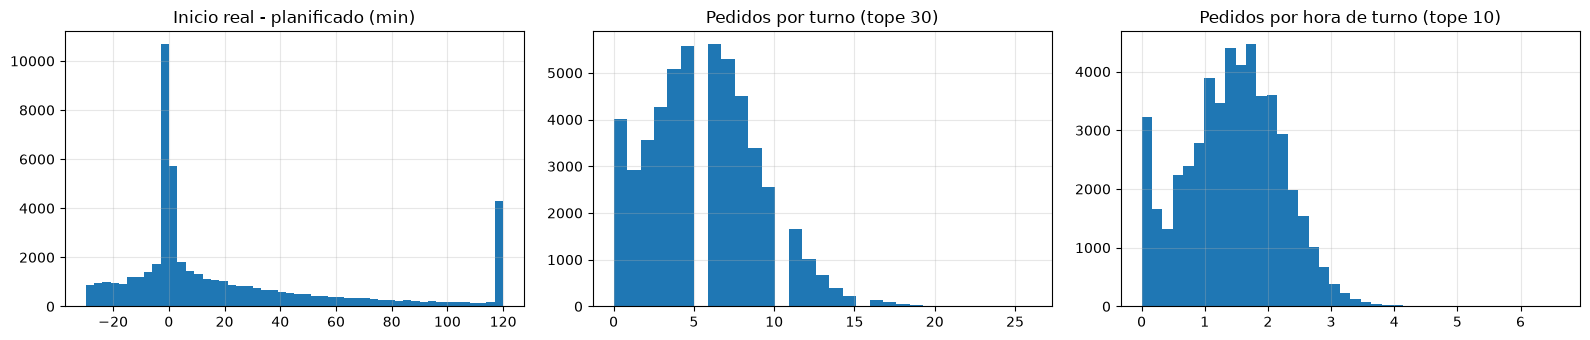

Spearman duración real / demora de inicio vs pedidos por turno:
dur_real_hs          0.50
demora_inicio_min   -0.21
pedidos              1.00
Name: pedidos, dtype: float64


In [58]:
# 8.3 Turno -> pedidos: cumplimiento, puntualidad y utilización
sh = tr[tr['inicio_turno_planificado'].between(DESDE, HASTA)].copy()
sh['conectado'] = sh['inicio_turno_real'].notna()
sh['dur_plan_hs'] = (sh['fin_turno_planificado'] - sh['inicio_turno_planificado']).dt.total_seconds() / 3600
sh['dur_real_hs'] = (sh['fin_turno_real'] - sh['inicio_turno_real']).dt.total_seconds() / 3600
sh['demora_inicio_min'] = (sh['inicio_turno_real'] - sh['inicio_turno_planificado']).dt.total_seconds() / 60
sh['dif_fin_min'] = (sh['fin_turno_real'] - sh['fin_turno_planificado']).dt.total_seconds() / 60
cnt = m.groupby('shift_id').agg(pedidos=('id_pedido', 'count'), entregados=('entregado', 'sum'), pago=('pago_total', 'sum'))
sh = sh.merge(cnt, left_on='shift_id', right_index=True, how='left')
sh[['pedidos', 'entregados', 'pago']] = sh[['pedidos', 'entregados', 'pago']].fillna(0)
sh['ped_hora'] = sh['pedidos'] / sh['dur_real_hs'].where(sh['dur_real_hs'] > .25)

con = sh[sh['conectado']]
print(f"Turnos planificados: {len(sh):,} | no conectados (sin horario real): {(~sh['conectado']).sum():,} ({(~sh['conectado']).mean():.1%})")
print(f"Turnos conectados sin ningún pedido: {(con['pedidos'] == 0).sum():,} ({(con['pedidos'] == 0).mean():.1%})")
print('\nPedidos por turno conectado:'); print(con['pedidos'].describe())
print('\nPuntualidad (min) y duración (hs):'); print(con[['demora_inicio_min', 'dif_fin_min', 'dur_plan_hs', 'dur_real_hs', 'ped_hora']].describe(percentiles=[.05, .5, .95]).T)

fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
con['demora_inicio_min'].clip(-30, 120).hist(ax=ax[0], bins=50); ax[0].set_title('Inicio real - planificado (min)')
con['pedidos'].clip(upper=30).hist(ax=ax[1], bins=31); ax[1].set_title('Pedidos por turno (tope 30)')
con['ped_hora'].clip(upper=10).hist(ax=ax[2], bins=40); ax[2].set_title('Pedidos por hora de turno (tope 10)')
plt.tight_layout(); plt.show()
print('Spearman duración real / demora de inicio vs pedidos por turno:')
print(con[['dur_real_hs', 'demora_inicio_min', 'pedidos']].corr(method='spearman').round(2)['pedidos'])

In [59]:
# 8.4 Perfil del rider vs cumplimiento y uso del turno
rd = sh.groupby('rider_id').agg(turnos=('shift_id', 'count'), no_show=('conectado', lambda s: 1 - s.mean()),
                                horas=('dur_real_hs', 'sum'), demora_med=('demora_inicio_min', 'median'),
                                ped_en_turno=('pedidos', 'sum'))
rd['ped_hora'] = rd['ped_en_turno'] / rd['horas'].where(rd['horas'] > 1)
pt = m.groupby('id_repartidor').agg(ped_total=('id_pedido', 'count'), pct_fuera_turno=('en_turno', lambda s: 1 - s.mean()))
rd = rd.join(pt, how='outer').join(riders.set_index('id_repartidor'))
rd[['turnos', 'ped_en_turno', 'ped_total']] = rd[['turnos', 'ped_en_turno', 'ped_total']].fillna(0)
print('Riders con turnos y con pedidos:', ((rd['turnos'] > 0) & (rd['ped_total'] > 0)).sum(), '| solo turnos:', ((rd['turnos'] > 0) & (rd['ped_total'] == 0)).sum(),
      '| solo pedidos:', ((rd['turnos'] == 0) & (rd['ped_total'] > 0)).sum())
act = rd[(rd['turnos'] >= 3) & (rd['ped_total'] >= 10)]
cols = ['turnos', 'no_show', 'demora_med', 'ped_hora', 'pct_fuera_turno', 'tasa_aceptacion', 'avg_batch', 'tenure_in_weeks']
print(f'\nCorrelación de Spearman ({len(act):,} riders con >= 3 turnos y >= 10 pedidos):'); print(act[cols].corr(method='spearman').round(2))
print('\nPor vehículo:'); print(act.groupby('vehicle_name')[['no_show', 'demora_med', 'ped_hora', 'pct_fuera_turno']].median().join(act.groupby('vehicle_name').size().rename('riders')))
act = act.assign(tenure_grupo=pd.cut(act['tenure_in_weeks'], [-1, 4, 12, 26, 52, 1e9], labels=['<=4 sem', '5-12', '13-26', '27-52', '>52']))
print('\nPor antigüedad:'); print(act.groupby('tenure_grupo', observed=True)[['no_show', 'demora_med', 'ped_hora', 'pct_fuera_turno']].median())

Riders con turnos y con pedidos: 3461 | solo turnos: 561 | solo pedidos: 2090

Correlación de Spearman (2,496 riders con >= 3 turnos y >= 10 pedidos):
                 turnos  no_show  demora_med  ped_hora  pct_fuera_turno  \
turnos             1.00     0.14        0.06      0.18            -0.41   
no_show            0.14     1.00        0.13     -0.11            -0.02   
demora_med         0.06     0.13        1.00     -0.13            -0.37   
ped_hora           0.18    -0.11       -0.13      1.00            -0.13   
pct_fuera_turno   -0.41    -0.02       -0.37     -0.13             1.00   
tasa_aceptacion   -0.16    -0.07       -0.18      0.32             0.08   
avg_batch         -0.20     0.36        0.33     -0.42            -0.04   
tenure_in_weeks    0.31    -0.03       -0.05      0.17            -0.05   

                 tasa_aceptacion  avg_batch  tenure_in_weeks  
turnos                     -0.16      -0.20             0.31  
no_show                    -0.07       0.36    

/var/folders/6z/2nkwfpvj5vdbpmc404rhvrsh0000gn/T/ipykernel_26992/2445701041.py:10: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  of = pd.concat([riders_por_hora(sh, 'inicio_turno_planificado', 'fin_turno_planificado').rename('planificados'),


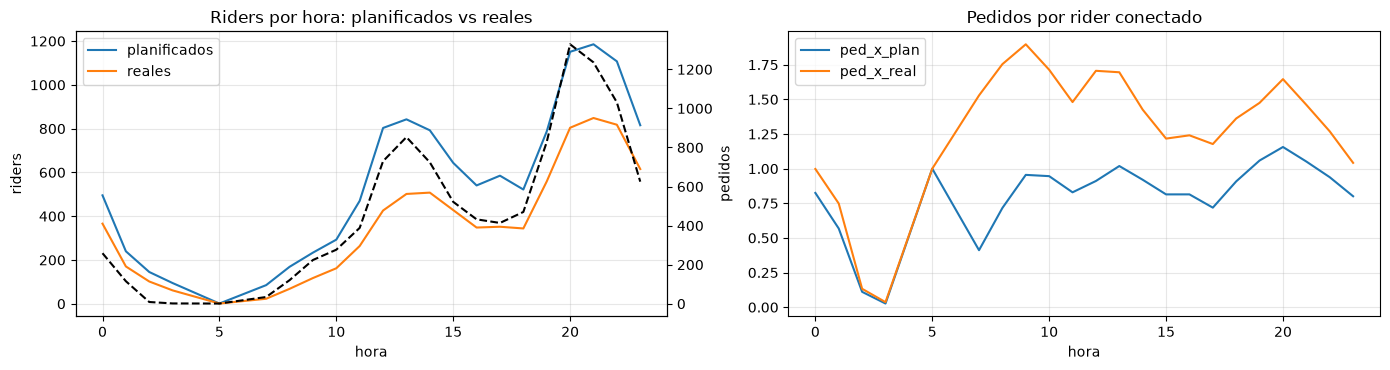

Spearman horario con pedidos:
planificados   0.94
reales         0.93
dtype: float64
Cumplimiento de la oferta (reales / planificados), promedio: 62.5%


In [60]:
# 8.5 Oferta planificada vs oferta real vs demanda, por hora del día
def riders_por_hora(df, ini, fin):
    d = df.dropna(subset=[ini, fin]).copy()
    d['h0'], d['h1'] = d[ini].dt.floor('h'), d[fin].dt.floor('h')
    d = d[(d['h1'] >= d['h0']) & ((d[fin] - d[ini]).dt.total_seconds() <= 24 * 3600)]
    r = d.loc[d.index.repeat(((d['h1'] - d['h0']).dt.total_seconds() // 3600 + 1).astype(int))].copy()
    r['h'] = r['h0'] + pd.to_timedelta(r.groupby(level=0).cumcount(), unit='h')
    return r.groupby('h')['rider_id'].nunique()

of = pd.concat([riders_por_hora(sh, 'inicio_turno_planificado', 'fin_turno_planificado').rename('planificados'),
                riders_por_hora(sh, 'inicio_turno_real', 'fin_turno_real').rename('reales'),
                m.groupby(m['rider_notified_at'].dt.floor('h'))['id_pedido'].count().rename('pedidos')], axis=1).dropna()
of['ped_x_plan'] = of['pedidos'] / of['planificados']; of['ped_x_real'] = of['pedidos'] / of['reales']
of['hora'] = of.index.hour
g = of.groupby('hora')[['planificados', 'reales', 'pedidos', 'ped_x_plan', 'ped_x_real']].mean()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
g[['planificados', 'reales']].plot(ax=ax[0], title='Riders por hora: planificados vs reales'); g['pedidos'].plot(ax=ax[0], secondary_y=True, color='k', ls='--', label='pedidos')
ax[0].right_ax.set_ylabel('pedidos'); ax[0].set_ylabel('riders')
g[['ped_x_plan', 'ped_x_real']].plot(ax=ax[1], title='Pedidos por rider conectado')
plt.tight_layout(); plt.show()
print('Spearman horario con pedidos:'); print(of[['planificados', 'reales']].corrwith(of['pedidos'], method='spearman').round(2))
print(f"Cumplimiento de la oferta (reales / planificados), promedio: {(of['reales'] / of['planificados']).mean():.1%}")


## 9. Reasignaciones y un-dispatch (reconstrucción desde las transiciones)
_Hipótesis: H8, H9, H10._

En `ped` (una fila por pedido) `pre_accept_undispatch` y `post_accept_undispatchs` dan 0. Acá se trabaja con **todas las filas** (`pedidos`, una por transición) para reconstruir cuántas veces se aceptó cada pedido y cuántos riders distintos pasaron por él.

**Definiciones de trabajo (proxy, a confirmar con el diccionario de datos):**
- *Pedido reasignado*: más de una transición `accepted`, o más de un `transicion_id_repartidor` distinto.
- *Abandono (proxy de un-dispatch post-aceptación)*: transición `accepted` hecha por un rider distinto al `id_repartidor` final del pedido.
- Significado de la transición `queued`: **revisar**.


In [61]:

# 9.1 ¿Hay valores de undispatch en alguna transición?
cols_u = ['pre_accept_undispatch', 'post_accept_undispatchs']
print('Filas con pre_accept_undispatch > 0 :', int((pedidos[cols_u[0]] > 0).sum()))
print('Filas con post_accept_undispatchs > 0:', int((pedidos[cols_u[1]] > 0).sum()))
print(pedidos.groupby('transicion')[cols_u].agg(['mean', 'max']).round(3))
mx = pedidos.groupby('id_pedido')[cols_u].max()
print('\nPedidos con algún undispatch (máximo por pedido > 0):'); print((mx > 0).mean().mul(100).round(2).astype(str) + ' %')


Filas con pre_accept_undispatch > 0 : 184476
Filas con post_accept_undispatchs > 0: 17000
            pre_accept_undispatch     post_accept_undispatchs    
                             mean max                    mean max
transicion                                                       
accepted                     0.00   0                    0.00   0
near_pickup                  0.00   0                    0.00   0
picked_up                    0.00   0                    0.00   0
queued                       0.92   1                    0.08   1

Pedidos con algún undispatch (máximo por pedido > 0):
pre_accept_undispatch      26.62 %
post_accept_undispatchs      4.4 %
dtype: str


In [62]:

# 9.2 Reconstrucción por pedido
pedidos['es_acept'] = (pedidos['transicion'] == 'accepted').astype(int)
pedidos['es_queued'] = (pedidos['transicion'] == 'queued').astype(int)
g = pedidos.groupby('id_pedido')
po = pd.DataFrame({'n_acept': g['es_acept'].sum(), 'n_queued': g['es_queued'].sum(), 'n_riders': g['transicion_id_repartidor'].nunique(),
                   'primer_acept': pedidos[pedidos['es_acept'] == 1].groupby('id_pedido')['creacion_transicion'].min()})
po['reasignado'] = (po['n_acept'] > 1) | (po['n_riders'] > 1)
rp = ped.set_index('id_pedido').join(po)
rp['entregado_ok'] = rp['entregado'] & (rp[TIEMPOS] >= 0).all(axis=1)
rp['min_perdidos'] = ((rp['rider_accepted_at'] - rp['primer_acept']).dt.total_seconds() / 60).clip(lower=0)

print(f"Pedidos: {len(rp):,} | reasignados: {int(rp['reasignado'].sum()):,} ({rp['reasignado'].mean():.2%})")
print('\nAceptaciones por pedido:'); print(rp['n_acept'].value_counts().sort_index().head(6))
print('\nRiders distintos por pedido:'); print(rp['n_riders'].value_counts().sort_index().head(6))
print('\nReasignado vs transición queued (para interpretar qué significa queued):')
print(pd.crosstab(rp['n_queued'].clip(upper=2), rp['reasignado'], normalize='index').round(3))


Pedidos: 329,196 | reasignados: 92,795 (28.19%)

Aceptaciones por pedido:
n_acept
1    314479
2     12821
3      1385
4       329
5       133
6        46
Name: count, dtype: int64

Riders distintos por pedido:
n_riders
1    236401
2     53214
3     18792
4      8586
5      4511
6      2581
Name: count, dtype: int64

Reasignado vs transición queued (para interpretar qué significa queued):
reasignado  False  True 
n_queued                
0            1.00   0.00
1            0.01   0.98
2            0.00   1.00


In [63]:

# 9.3 Costo de la reasignación en nivel de servicio
ent = rp[rp['entregado_ok']]
cmp_ = rp.groupby('reasignado').agg(pedidos=('rider_notified_at', 'size'), cancelados=('order_status', lambda s: (s == 'cancelled').mean()),
                                    pago_total=('pago_total', 'mean'))
cmp_ = cmp_.join(ent.groupby('reasignado')[['t_aceptacion', 't_a_local', 't_espera_local', 't_viaje', 't_total']].median())
print(cmp_.round(3))
re = rp[rp['reasignado']]
print('\nMinutos entre la primera aceptación y la aceptación final (pedidos reasignados):'); print(re['min_perdidos'].describe(percentiles=[.5, .9]).round(2))
MIN_PERDIDOS_REASIG = re['min_perdidos'].mean()
CANC_REASIG, CANC_NO = cmp_.loc[True, 'cancelados'], cmp_.loc[False, 'cancelados']


            pedidos  cancelados  pago_total  t_aceptacion  t_a_local  \
reasignado                                                             
False        236401        0.01       20.45          0.16       2.68   
True          92795        0.01       22.40          0.20       3.06   

            t_espera_local  t_viaje  t_total  
reasignado                                    
False                 4.25     8.37    16.96  
True                  3.06    10.23    18.09  

Minutos entre la primera aceptación y la aceptación final (pedidos reasignados):
count   92,795.00
mean         2.73
std          9.01
min          0.00
50%          0.00
90%          9.71
max        189.16
Name: min_perdidos, dtype: float64


In [64]:

# 9.4 Abandono por rider (proxy de un-dispatch) y su relación con el perfil
acc = pedidos[pedidos['es_acept'] == 1].copy()
acc['abandono'] = acc['transicion_id_repartidor'] != acc['id_repartidor']
rab = acc.groupby('transicion_id_repartidor').agg(aceptados=('id_pedido', 'count'), abandonos=('abandono', 'sum'))
rab['tasa_abandono'] = rab['abandonos'] / rab['aceptados']
print(f"Tasa global de abandono (proxy de un-dispatch): {rab['abandonos'].sum() / rab['aceptados'].sum():.2%}  (consigna: ~2%)")
rab = rab.join(riders.drop_duplicates('id_repartidor').set_index('id_repartidor'))
rab = rab.join(rd[['no_show', 'demora_med', 'ped_hora']], how='left')
ra = rab[rab['aceptados'] >= 20].copy()
ra['tenure_grupo'] = pd.cut(ra['tenure_in_weeks'], [-1, 4, 12, 26, 52, 1e9], labels=['<=4 sem', '5-12', '13-26', '27-52', '>52'])
ra['acept_tramo'] = pd.cut(ra['tasa_aceptacion'], [0, .5, .7, .85, .999, 1.0], include_lowest=True)
print(f'\nRiders con >= 20 aceptaciones: {len(ra):,}')
print('\nTasa de abandono media por vehículo:'); print(ra.groupby('vehicle_name')['tasa_abandono'].agg(['mean', 'count']).round(4))
print('\nPor antigüedad:'); print(ra.groupby('tenure_grupo', observed=True)['tasa_abandono'].agg(['mean', 'count']).round(4))
print('\nPor tramo de tasa_aceptacion del rider:'); print(ra.groupby('acept_tramo', observed=True)['tasa_abandono'].agg(['mean', 'count']).round(4))
print('\nSpearman de la tasa de abandono con el perfil del rider:')
print(ra[['tasa_abandono', 'tasa_aceptacion', 'avg_batch', 'tenure_in_weeks', 'no_show', 'demora_med', 'ped_hora']].corr(method='spearman')['tasa_abandono'].round(2))


Tasa global de abandono (proxy de un-dispatch): 5.01%  (consigna: ~2%)

Riders con >= 20 aceptaciones: 2,566

Tasa de abandono media por vehículo:
              mean  count
vehicle_name             
Automovil     0.10      8
Bicicleta     0.05   1654
CAFE - Bici   0.05     24
CAFE - Moto   0.07      6
Motocicleta   0.05    874

Por antigüedad:
              mean  count
tenure_grupo             
<=4 sem       0.06     60
5-12          0.05    188
13-26         0.05    410
27-52         0.05    596
>52           0.05   1312

Por tramo de tasa_aceptacion del rider:
               mean  count
acept_tramo               
(-0.001, 0.5]  0.09    295
(0.5, 0.7]     0.06    640
(0.7, 0.85]    0.05    765
(0.85, 0.999]  0.04    817
(0.999, 1.0]   0.04     49

Spearman de la tasa de abandono con el perfil del rider:
tasa_abandono      1.00
tasa_aceptacion   -0.28
avg_batch          0.21
tenure_in_weeks    0.04
no_show            0.14
demora_med         0.10
ped_hora          -0.33
Name: tasa_aband

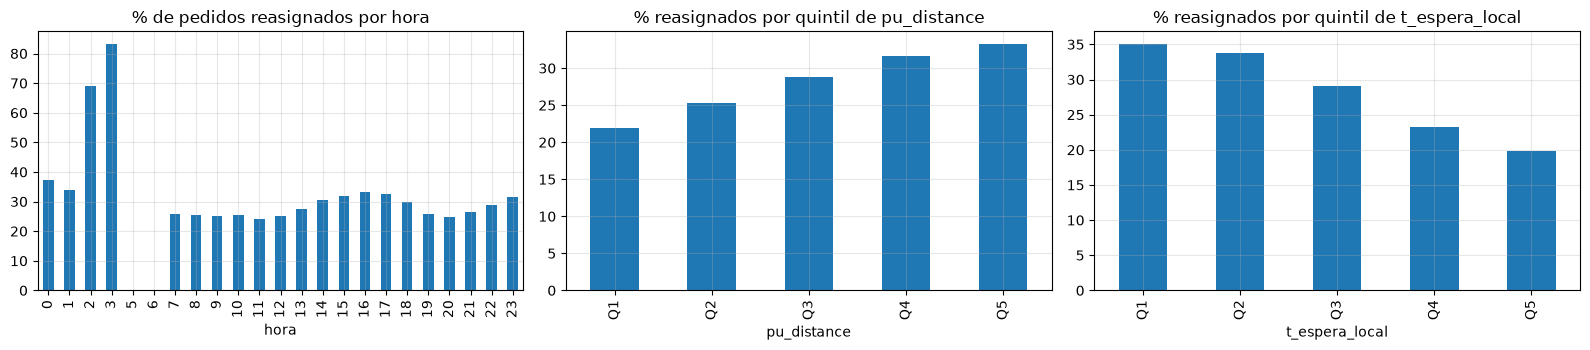

In [65]:

# 9.5 ¿Dónde se reasigna? Hora, distancia al retiro y espera en el local (H10)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
rp.groupby('hora')['reasignado'].mean().mul(100).plot.bar(ax=ax[0], title='% de pedidos reasignados por hora')
for a, v in zip(ax[1:], ['pu_distance', 't_espera_local']):
    q = pd.qcut(rp[v].rank(method='first'), 5, labels=['Q1', 'Q2', 'Q3', 'Q4', 'Q5'])
    rp.groupby(q, observed=True)['reasignado'].mean().mul(100).plot.bar(ax=a, title=f'% reasignados por quintil de {v}')
plt.tight_layout(); plt.show()



## 10. Escenarios de impacto (nivel de servicio, UTR y CPO)
_Hipótesis: H11._

Los valores de partida de la consigna (aceptación ~70%, un-dispatch ~2%) y los observados en los datos se combinan con **parámetros de sensibilidad**. Lo que no se puede medir con estos datos (minutos que suma cada oferta no aceptada, costo total por orden) queda como parámetro a **revisar**: las tablas son análisis de sensibilidad, no estimaciones puntuales.


In [66]:

# 10.1 Aceptación -> rechazos por orden -> Delivery Time
P_ACT = 0.70                       # consigna
OBJETIVOS = [0.75, 0.80, 0.85, 0.90]
MIN_POR_RECHAZO = [0.5, 1, 2, 3]   # SENSIBILIDAD (no medido): minutos que suma a la orden cada oferta no aceptada. Revisar
N = ped['id_pedido'].nunique()     # pedidos del período de los datos

esc = pd.DataFrame({'aceptacion': [P_ACT] + OBJETIVOS})
esc['ofertas_por_orden'] = 1 / esc['aceptacion']                  # supuesto: ofertas independientes, una a la vez
esc['rechazos_por_orden'] = esc['ofertas_por_orden'] - 1
esc['rechazos_evitados'] = (esc.loc[0, 'rechazos_por_orden'] - esc['rechazos_por_orden']) * N
for m_ in MIN_POR_RECHAZO:
    esc[f'min_por_orden (x{m_} min)'] = (esc.loc[0, 'rechazos_por_orden'] - esc['rechazos_por_orden']) * m_
mediana_total = ent['t_total'].median()
print(f'Pedidos del período: {N:,} | Delivery Time mediano observado: {mediana_total:.1f} min')
print(esc.round(3).to_string(index=False))


Pedidos del período: 329,196 | Delivery Time mediano observado: 17.3 min
 aceptacion  ofertas_por_orden  rechazos_por_orden  rechazos_evitados  min_por_orden (x0.5 min)  min_por_orden (x1 min)  min_por_orden (x2 min)  min_por_orden (x3 min)
       0.70               1.43                0.43               0.00                      0.00                    0.00                    0.00                    0.00
       0.75               1.33                0.33          31,352.00                      0.05                    0.10                    0.19                    0.29
       0.80               1.25                0.25          58,785.00                      0.09                    0.18                    0.36                    0.54
       0.85               1.18                0.18          82,990.59                      0.13                    0.25                    0.50                    0.76
       0.90               1.11                0.11         104,506.67                  

In [67]:

# 10.2 Aceptación -> UTR -> CPO (asociación entre riders; usar como cota, no como efecto causal)
d = act.dropna(subset=['tasa_aceptacion', 'ped_hora']).copy()
d['ped_hora'] = d['ped_hora'].clip(upper=d['ped_hora'].quantile(.99))
pend, ord_ = np.polyfit(d['tasa_aceptacion'], d['ped_hora'], 1)
UTR0 = prod['ped_hora'].median(); PAGO_HORA0 = prod['pago_hora'].median()
CPO0 = pe['pago_total'].mean()      # solo pago al rider; el CPO completo incluye otros costos: revisar
print(f'Pendiente rider-nivel: +{pend * 0.10:.3f} pedidos/hora por cada +10 pp de tasa_aceptacion ({len(d):,} riders)')
print(f'UTR actual (mediana rider-día): {UTR0:.2f} ped/h | pago por hora (mediana): {PAGO_HORA0:.1f} | pago medio por pedido: {CPO0:.2f}')
r = pd.DataFrame({'delta_aceptacion_pp': [(o - P_ACT) * 100 for o in OBJETIVOS]}, index=OBJETIVOS)
r['delta_UTR_%'] = pend * (r['delta_aceptacion_pp'] / 100) / UTR0 * 100
r['UTR_nuevo'] = UTR0 * (1 + r['delta_UTR_%'] / 100)
r['CPO_pago_nuevo'] = PAGO_HORA0 / r['UTR_nuevo']          # supuesto de la consigna: se capitaliza el UTR manteniendo el ingreso/hora
r['ahorro_por_orden'] = PAGO_HORA0 / UTR0 - r['CPO_pago_nuevo']
r['ahorro_total_periodo'] = r['ahorro_por_orden'] * N
print(r.round(3).to_string())


Pendiente rider-nivel: +0.073 pedidos/hora por cada +10 pp de tasa_aceptacion (2,481 riders)
UTR actual (mediana rider-día): 1.48 ped/h | pago por hora (mediana): 29.8 | pago medio por pedido: 20.96
      delta_aceptacion_pp  delta_UTR_%  UTR_nuevo  CPO_pago_nuevo  ahorro_por_orden  ahorro_total_periodo
0.75                 5.00         2.48       1.52           19.62              0.49            160,106.92
0.80                10.00         4.96       1.55           19.16              0.95            312,651.48
0.85                15.00         7.44       1.59           18.72              1.39            458,157.10
0.90                20.00         9.91       1.63           18.29              1.81            597,100.01


In [68]:

# 10.3 Un-dispatch -> reasignaciones evitadas -> minutos y cancelaciones
UND_ACT = 0.02                      # consigna
UND_OBJ = [0.015, 0.01, 0.005]
u = pd.DataFrame({'undispatch_objetivo': UND_OBJ})
u['ordenes_evitadas'] = (UND_ACT - u['undispatch_objetivo']) * N
u['min_ahorrados'] = u['ordenes_evitadas'] * MIN_PERDIDOS_REASIG       # medido en 9.3
u['cancelaciones_evitadas'] = u['ordenes_evitadas'] * (CANC_REASIG - CANC_NO)
print(f'Minutos medios perdidos por pedido reasignado (9.3): {MIN_PERDIDOS_REASIG:.2f} | cancelación reasignados {CANC_REASIG:.2%} vs resto {CANC_NO:.2%}')
print(u.round({'undispatch_objetivo': 4, 'ordenes_evitadas': 0, 'min_ahorrados': 0, 'cancelaciones_evitadas': 1}).to_string(index=False))
print('\nNota: el 2% de la consigna se usa como línea de base; la tasa reconstruida en 9.2 / 9.4 es un proxy a validar.')


Minutos medios perdidos por pedido reasignado (9.3): 2.73 | cancelación reasignados 0.51% vs resto 0.48%
 undispatch_objetivo  ordenes_evitadas  min_ahorrados  cancelaciones_evitadas
                0.01          1,646.00       4,497.00                    0.60
                0.01          3,292.00       8,994.00                    1.10
                0.01          4,938.00      13,492.00                    1.70

Nota: el 2% de la consigna se usa como línea de base; la tasa reconstruida en 9.2 / 9.4 es un proxy a validar.



## 11. Validación de hipótesis
_Resultados con lo ya observado en las secciones 3 a 8. Las filas en **revisar** dependen de ejecutar las secciones 9 y 10 con los datos._

| # | Resultado | Evidencia | Acción sugerida | Impacto esperado |
|---|---|---|---|---|
| H1 | Validada | Oferta real = 62,5% de la planificada; 34,6% de los turnos planificados no se conecta; la brecha es mayor en los picos (20 hs: ~1.180 planificados vs ~800 reales) | revisar | revisar |
| H2 | Validada | Correlación horaria con pedidos: 0,94 (planificada) y 0,93 (real) | revisar | revisar |
| H3 | Parcial | Entre riders (≥3 turnos y ≥10 pedidos): `tasa_aceptacion` con `ped_hora` +0,32; en rider-día, con `pago_hora` +0,28. Es asociación | revisar | Sección 10.2 |
| H4 | Parcial | `pago_base` con distancia ~0,55; `pago_total` casi plano frente a `t_total`; la espera en el local es 29% del tiempo total | revisar | revisar |
| H5 | Parcial | Pago por pedido de 23–33 entre 20–2 hs vs ~18 de día; incentivos sin relación con la distancia. La hora confunde el efecto sobre el tiempo | revisar | revisar |
| H6 | Validada (asociación) | `avg_batch` con `tasa_aceptacion` −0,49, no-show +0,36, `ped_hora` −0,42. Definición de `avg_batch`: **revisar** | revisar | revisar |
| H7 | Parcial | Antigüedad con `tasa_aceptacion` 0,00; con demora de inicio: 2,1 min (>52 sem) vs 6,8 (≤4 sem); `ped_hora` 1,51 vs 1,25 | revisar | revisar |
| H8 | revisar | Sección 9.2 y 9.4 | revisar | revisar |
| H9 | revisar | Sección 9.3 | revisar | revisar |
| H10 | revisar | Sección 9.5 | revisar | revisar |
| H11 | revisar | Sección 10 (sensibilidad) | revisar | revisar |

**Método para cuantificar el impacto:** minutos ahorrados = (rechazos o reasignaciones evitados) × minutos que suma cada uno × pedidos del período; ahorro de CPO = pago por hora / UTR, antes y después. El costo por minuto y el CPO completo requieren datos de la empresa: **revisar**.



## 12. Hallazgos (a completar con los resultados de las secciones 9 y 10)
_Lo que no se pueda sustentar con los datos o con la teoría de la materia: dejar en blanco y marcar **revisar**._

- **Calidad de datos:** una fila por transición (1.217.343 filas, 329.196 pedidos); undispatch en 0 en la última fila de cada pedido; 446 `id_repartidor` duplicados en riders; datos de un solo mes (30/4 a 31/5 de 2024).
- **Disponibilidad:** 34,6% de turnos sin conectar; oferta real = 62,5% de la planificada; 12,4% de los pedidos se entrega fuera de un turno registrado.
- **Aceptación y rendimiento:** UTR ~1,45 pedidos por hora de turno; aceptar más se asocia con más pedidos por hora y más ingreso por hora; antigüedad no explica aceptación; `avg_batch` separa dos perfiles de rider (**revisar** su definición).
- **Pago y esfuerzo:** el pago sigue la distancia, no el tiempo ni la espera (29% del tiempo total).
- **Ejecución (reasignaciones, un-dispatch):** revisar (sección 9).
- **Impacto en servicio, UTR y CPO:** revisar (sección 10).
